# Slot 7 · Fix it: fix the data, then ask again

**AI Days 2026 · Teaching Machines to Read DNA** — Technion

In Slot 6 two numbers — how much G+C and U a sequence has — already separated bound from unbound
RNA. That is a property of **how the negatives were chosen**, not of AGO2. A model trained on
these data can score well by learning composition, and we would never know.

The fix is a **control**: build new negatives that have the *same* composition (and length) as the
positives. Then composition carries no information, and whatever score is left must come from
something else.

| cell | what you do |
|---|---|
| `#@title ... run this cell, nothing to change` | just run it |
| `# TODO-N` with `# === Your code here ===` | write it (yourself or with an assistant), then **check** it |
| `#@title Stuck? ...` | run it only if your TODO doesn't pass its check: it defines our version |

In [1]:
#@title Setup - run this cell, nothing to change { display-mode: "form" }
import os, time, urllib.request
from pathlib import Path
import numpy as np
import torch
from torch import nn, optim
from sklearn.metrics import roc_auc_score

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU - Runtime > Change runtime type > T4 GPU")

# Where the workshop files live. Either one direct-download link per file (FILE_URLS, e.g. SharePoint
# "anyone with the link" + download=1), or one folder URL (DATA_URL, e.g. a Hugging Face dataset repo).
FILE_URLS = {}
DATA_URL = os.environ.get("AIDAYS_DATA_URL", "")
DATA_DIR = Path(os.environ.get("AIDAYS_DATA_DIR", "data"))
DATA_DIR.mkdir(exist_ok=True)

try:
    from google.colab import files as _colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


def fetch(name):
    """Return the local path of a workshop file, downloading it first if needed."""
    path = DATA_DIR / name
    if not path.exists():
        url = FILE_URLS.get(name) or (f"{DATA_URL.rstrip('/')}/{name}" if DATA_URL else "")
        if not url:
            raise FileNotFoundError(f"{path} not found and no download link is set for it")
        t = time.time()
        urllib.request.urlretrieve(url, path)
        print(f"downloaded {name} ({path.stat().st_size / 1e6:.1f} MB) in {time.time() - t:.1f}s")
    return path


def download_outputs(*names):
    """End of a notebook: save your results to your laptop so the next notebook can use them."""
    for n in names:
        p = DATA_DIR / n
        if not p.exists():
            print(f"{n}: not found (did the cell that makes it run?)")
        elif IN_COLAB:
            _colab_files.download(str(p))
        else:
            print(f"{n}: saved at {p}")


def upload_yours():
    """Start of a notebook: upload the files you downloaded at the end of an earlier notebook."""
    if not IN_COLAB:
        print(f"not in Colab: copy your files into {DATA_DIR}")
        return
    import re
    for n, b in _colab_files.upload().items():
        clean = re.sub(r" \(\d+\)(?=\.[^.]+$)", "", n)   # "my_cnn (1).pt" -> "my_cnn.pt" (browser renames)
        (DATA_DIR / clean).write_bytes(b)
        print("uploaded", n, "->", clean)

device: cuda | NVIDIA A30


In [2]:
#@title Data helpers - run this cell, nothing to change { display-mode: "form" }
MAX_LEN  = 501          # fixed global length (pad / truncate)
ALPHABET = "ACGU"       # order = the 4 rows of the one-hot matrix
FILES = {split: (f"CLIPSEQ_AGO2.{split}.positives.fa", f"CLIPSEQ_AGO2.{split}.negatives.fa")
         for split in ("train", "ls")}


def read_fasta(path, label):
    """Return (sequences, labels) from a FASTA file, all with the same label.

    The files mix the DNA letter T and the RNA letter U for the same base,
    so we normalise everything to U.
    """
    seqs, labs = [], []
    with Path(path).open() as fh:
        for line in fh:
            if line.startswith(">"):
                continue
            seqs.append(line.strip().upper().replace("T", "U"))
            labs.append(label)
    return seqs, labs


def read_split(split):
    """'train' or 'ls' (the held-out validation set) -> (sequences, labels as a numpy array)."""
    pos, neg = FILES[split]
    p, lp = read_fasta(fetch(pos), 1)
    n, ln = read_fasta(fetch(neg), 0)
    return p + n, np.array(lp + ln)


_LUT = np.full(256, -1, dtype=np.int64)
for _i, _b in enumerate(ALPHABET):
    _LUT[ord(_b)] = _i


def encode_batch(seqs, max_len=MAX_LEN):
    """List of RNA strings -> one-hot FloatTensor (B, 1, 4, max_len).

    Pads/truncates to max_len; padding and unknown bases stay uniform 0.25.
    """
    X = np.full((len(seqs), 1, 4, max_len), 0.25, dtype=np.float32)
    for b, s in enumerate(seqs):
        idx = _LUT[np.frombuffer(s[:max_len].encode(), dtype=np.uint8)]
        pos = np.nonzero(idx >= 0)[0]
        X[b, 0, :, pos] = 0.0
        X[b, 0, idx[pos], pos] = 1.0
    return torch.from_numpy(X)

In [3]:
#@title Foundation-model helpers - run this cell, nothing to change { display-mode: "form" }
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import transformers
transformers.logging.set_verbosity_error()

FM_REPO = "RaphaelMourad/Mistral-DNA-v1-17M-hg38"            # 16M parameters, pretrained on the human genome
NT_REPO = "InstaDeepAI/nucleotide-transformer-500m-human-ref"  # 486M parameters


def to_dna(seq):
    """The DNA language models read T, not U."""
    return seq.replace("U", "T")


def workshop_data(n_train=12000, seed=0):
    """Train: a fixed random 12k subset of the training file (the same in Slots 5-6).
    Test: the held-out 'ls' set - the same test set the Slot 2 CNN was measured on."""
    seqs, y = read_split("train")
    tr = np.random.default_rng(seed).permutation(len(seqs))[:n_train]
    test_seqs, test_y = read_split("ls")
    return [seqs[i] for i in tr], y[tr], test_seqs, test_y


def load_fm(repo=FM_REPO):
    """Download (first time only) and load a DNA language model + its tokenizer."""
    from transformers import AutoModel, AutoTokenizer
    tok = AutoTokenizer.from_pretrained(repo, trust_remote_code=True)
    model = AutoModel.from_pretrained(repo, trust_remote_code=True).to(DEVICE).eval()
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token or tok.unk_token
    return tok, model

In [4]:
#@title Embedding + probe helpers (written in Slot 5) - run this cell, nothing to change { display-mode: "form" }
@torch.no_grad()
def embed(tok, model, seqs, batch=128):
    """List of DNA strings -> (N, hidden) numpy array: the mean of the last layer over real tokens."""
    model.eval()
    out = []
    for i in range(0, len(seqs), batch):
        enc = tok(seqs[i:i + batch], return_tensors="pt", padding=True, truncation=True, max_length=512)
        ids, mask = enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            h = model(input_ids=ids, attention_mask=mask, output_hidden_states=True).hidden_states[-1].float()
        m = mask.unsqueeze(-1).float()
        out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
    return np.concatenate(out)


def probe_auc(E_train, y_train, E_test, y_test, C=0.1):
    """Fit a linear probe (logistic regression) on the training vectors; AUROC on the test vectors."""
    probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=C))
    probe.fit(E_train, y_train)
    return roc_auc_score(y_test, probe.predict_proba(E_test)[:, 1]), probe

In [5]:
#@title The CNN from Slot 2 - run this cell, nothing to change { display-mode: "form" }
class GlobalCNN(nn.Module):
    """The Slot 2 network: one-hot (N,1,4,501) -> one binding score (logit) per sequence."""

    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 10, (4, 10)), nn.ReLU(),
            nn.MaxPool2d((1, 3)),
            nn.Conv2d(10, 20, (1, 5)), nn.ReLU(),
            nn.MaxPool2d((1, 3)),
            nn.Flatten(),
            nn.Linear(20 * 53, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


@torch.no_grad()
def score_sequences(model, seqs, batch=1024):
    """The model's binding probability for each sequence (list of RNA strings)."""
    model.eval()
    out = []
    for i in range(0, len(seqs), batch):
        X = encode_batch(seqs[i:i + batch])
        out.append(torch.sigmoid(model(X.to(DEVICE))).cpu().numpy())
    return np.concatenate(out)


def load_cnn(mine="my_cnn.pt", ours="cnn.pt"):
    """Your CNN from Slot 2 if you uploaded it and it loads; otherwise ours."""
    model = GlobalCNN().to(DEVICE)
    if (DATA_DIR / mine).exists():
        try:
            model.load_state_dict(torch.load(DATA_DIR / mine, map_location=DEVICE))
            print("loaded YOUR CNN from Slot 2")
            return model.eval()
        except Exception as e:
            print(f"your {mine} doesn't match the Slot 2 architecture ({type(e).__name__}) - using ours")
    model.load_state_dict(torch.load(fetch(ours), map_location=DEVICE))
    print("loaded the reference CNN")
    return model.eval()

In [6]:
#@title Shortcut toolkit - run this cell, nothing to change { display-mode: "form" }
from collections import defaultdict


def gc_u(seqs):
    """(N, 2): the fraction of G+C letters and the fraction of U (or T) letters in each sequence."""
    out = np.zeros((len(seqs), 2))
    for i, s in enumerate(seqs):
        n = max(len(s), 1)
        out[i] = ((s.count("G") + s.count("C")) / n, (s.count("U") + s.count("T")) / n)
    return out


_K = {b: i for i, b in enumerate("ACGT")}
_K["U"] = 3


def kmer_counts(seqs, k=5):
    """(N, 4^k): how often each k-letter word appears in each sequence (as a fraction)."""
    M = np.zeros((len(seqs), 4 ** k), dtype=np.float32)
    for r, s in enumerate(seqs):
        code, valid = 0, 0
        for j, ch in enumerate(s):
            v = _K.get(ch, -1)
            if v < 0:
                valid = 0
                continue
            code = (code * 4 + v) % (4 ** k)
            valid += 1
            if valid >= k:
                M[r, code] += 1
        M[r] /= max(M[r].sum(), 1)
    return M


def dinuc_shuffle(seq, rng):
    """Shuffle a sequence but keep every letter-pair count (Altschul-Erickson / Eulerian walk).

    The result has exactly the same letters, the same GC, the same letter pairs - but any longer
    pattern (a motif) is destroyed.
    """
    if len(seq) < 3:
        return seq
    edges = defaultdict(list)
    for a, b in zip(seq[:-1], seq[1:]):
        edges[a].append(b)
    last = seq[-1]
    while True:  # random spanning tree of "last exits" pointing towards the final letter
        last_edge = {v: edges[v][rng.integers(len(edges[v]))] for v in edges if v != last}
        ok = True
        for v in last_edge:
            seen, u = set(), v
            while u != last:
                if u in seen or u not in last_edge:
                    ok = False
                    break
                seen.add(u)
                u = last_edge[u]
            if not ok:
                break
        if ok:
            break
    order = {}
    for v, lst in edges.items():
        lst = list(lst)
        if v in last_edge:
            lst.remove(last_edge[v])
            rng.shuffle(lst)
            lst.append(last_edge[v])
        else:
            rng.shuffle(lst)
        order[v] = lst
    out, u, ptr = [seq[0]], seq[0], defaultdict(int)
    for _ in range(len(seq) - 1):
        nxt = order[u][ptr[u]]
        ptr[u] += 1
        out.append(nxt)
        u = nxt
    return "".join(out)

## 1. Composition-matched negatives

We sort every training sequence into a bin by its G+C fraction, U fraction and length. Inside each
bin we keep **as many unbound as bound** sequences, dropping the rest. Afterwards the two classes
have the same composition, bin by bin.

original: train 64,764 | test 3,000 | bound 52%
matched : train 64,764 | test 3,000 | bound 50%


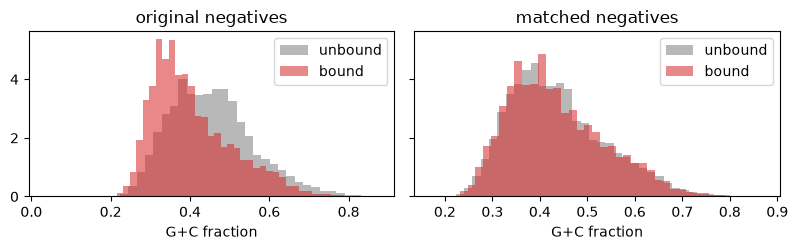

In [7]:
#@title Build the matched data set - run this cell, nothing to change { display-mode: "form" }
import matplotlib.pyplot as plt

all_seqs, all_y = read_split("train")


def matched_indices(seqs, y, seed=0):
    rng = np.random.default_rng(seed)
    C = gc_u(seqs)
    L = np.array([len(s) for s in seqs])
    key = (np.clip((C[:, 0] * 12 / 0.8).astype(int), 0, 11) * 100
           + np.clip((C[:, 1] * 12 / 0.6).astype(int), 0, 11) * 10
           + np.clip((L - 130) // 60, 0, 4))
    keep = []
    for k in np.unique(key[y == 1]):
        p = np.nonzero((key == k) & (y == 1))[0]
        n = np.nonzero((key == k) & (y == 0))[0]
        m = min(len(p), len(n))
        keep += list(rng.choice(p, m, replace=False)) + list(rng.choice(n, m, replace=False))
    keep = np.array(keep)
    rng.shuffle(keep)
    return keep


N_TEST = 3000
m_idx = matched_indices(all_seqs, all_y)
o_idx = np.random.default_rng(1).permutation(len(all_seqs))[:len(m_idx)]   # same size, original negatives
BENCH = {}
for name, idx in (("original", o_idx), ("matched", m_idx)):
    te, tr = idx[:N_TEST], idx[N_TEST:]
    BENCH[name] = ([all_seqs[i] for i in tr], all_y[tr], [all_seqs[i] for i in te], all_y[te])
    print(f"{name:8s}: train {len(tr):,} | test {len(te):,} | bound {all_y[tr].mean():.0%}")

fig, ax = plt.subplots(1, 2, figsize=(8, 2.6), sharey=True)
for a, name in zip(ax, BENCH):
    S, y = BENCH[name][0], BENCH[name][1]
    g = gc_u(S)[:, 0]
    for lab, c, lbl in ((0, "tab:grey", "unbound"), (1, "tab:red", "bound")):
        a.hist(g[y == lab], bins=40, alpha=.55, color=c, density=True, label=lbl)
    a.set_title(f"{name} negatives"); a.set_xlabel("G+C fraction"); a.legend()
plt.tight_layout(); plt.show()

Two benchmarks of **equal size**, drawn from the same file: `original` keeps the negatives as they
were, `matched` uses the composition-matched ones. Every model below is trained and tested on
**both**, so any difference comes from the negatives, not from the test set.

### TODO-1 · One function, two benchmarks

**Build** the body of `shortcut_scores(train_seqs, train_y, test_seqs, test_y)`: it gets the first
12,000 training sequences as `tr`, `ytr` and must **return a dict with exactly these three keys**,
each holding a test AUROC (a number), computed exactly as in Slot 6:

| key | features for `probe_auc` |
|---|---|
| `"G+C and U content only (2 numbers)"` | `gc_u(tr)` and `gc_u(test_seqs)` |
| `"5-letter word counts (1,024 numbers)"` | `kmer_counts(tr, 5)` and `kmer_counts(test_seqs, 5)` |
| `"Mistral-DNA + probe (frozen)"` | `embed(tok, fm, [to_dna(s) for s in tr])`, same for `test_seqs` |

**Gotchas to tell your assistant:** `probe_auc(F_train, y_train, F_test, y_test)` returns a
**tuple `(auc, probe)`**: store only the `auc`. `embed(tok, model, seqs)` needs DNA letters, hence
`to_dna`. The function is called twice (once per benchmark), so it must not use global data.

**Check:** on `matched`, the 2-number model must be close to **0.5** (≈0.51). If it isn't, stop and
find out why. Expected on `original`: 0.64 · 0.76 · 0.81.

In [8]:
tok, fm = load_fm(FM_REPO)


def shortcut_scores(train_seqs, train_y, test_seqs, test_y, n=12000):
    tr, ytr = train_seqs[:n], train_y[:n]
    # TODO-1: return the three AUROCs as a dict (keys as in the text above)
    # === Your code here ===
    ...
    # === End of your code ===


scores = {name: shortcut_scores(*BENCH[name]) for name in BENCH}
for k in scores["original"]:
    print(f"{k:38s} original {scores['original'][k]:.3f} | matched {scores['matched'][k]:.3f}")

Loading weights:   0%|          | 0/74 [00:00<?, ?it/s]

TypeError: 'NoneType' object is not iterable

In [9]:
#@title Stuck? Run this only if TODO-1 failed its check - it computes the three scores for you { display-mode: "form" }
def shortcut_scores(train_seqs, train_y, test_seqs, test_y, n=12000):
    tr, ytr = train_seqs[:n], train_y[:n]
    return {"G+C and U content only (2 numbers)": probe_auc(gc_u(tr), ytr, gc_u(test_seqs), test_y)[0],
            "5-letter word counts (1,024 numbers)": probe_auc(kmer_counts(tr, 5), ytr, kmer_counts(test_seqs, 5), test_y)[0],
            "Mistral-DNA + probe (frozen)": probe_auc(embed(tok, fm, [to_dna(s) for s in tr]), ytr,
                                                      embed(tok, fm, [to_dna(s) for s in test_seqs]), test_y)[0]}
scores = {name: shortcut_scores(*BENCH[name]) for name in BENCH}
for k in scores["original"]:
    print(f"{k:38s} original {scores['original'][k]:.3f} | matched {scores['matched'][k]:.3f}")

G+C and U content only (2 numbers)     original 0.637 | matched 0.510
5-letter word counts (1,024 numbers)   original 0.762 | matched 0.725
Mistral-DNA + probe (frozen)           original 0.806 | matched 0.770


## 2. Retrain the CNN on both benchmarks

Same architecture as Slot 2, 6 epochs on each training set (~1.5 minutes on a T4 for both).

In [10]:
#@title Retrain the CNN twice - run this cell, nothing to change { display-mode: "form" }
from torch.utils.data import DataLoader, TensorDataset
for name in BENCH:
    S_tr, y_tr, S_te, y_te = BENCH[name]
    t0 = time.time()
    torch.manual_seed(SEED)
    cnn_b = GlobalCNN().to(DEVICE)
    cnn_opt = optim.Adam(cnn_b.parameters(), lr=1e-3, weight_decay=1e-4)
    cnn_crit = nn.BCEWithLogitsLoss()
    loader = DataLoader(TensorDataset(encode_batch(S_tr), torch.tensor(y_tr, dtype=torch.float32)),
                        batch_size=256, shuffle=True, drop_last=True)
    for ep in range(6):
        cnn_b.train()
        for X, y in loader:
            cnn_opt.zero_grad()
            cnn_crit(cnn_b(X.to(DEVICE)), y.to(DEVICE)).backward()
            cnn_opt.step()
    scores[name]["CNN (Slot 2 architecture)"] = roc_auc_score(y_te, score_sequences(cnn_b, S_te))
    print(f"CNN, {name:8s}: {scores[name]['CNN (Slot 2 architecture)']:.3f}  ({time.time() - t0:.0f}s)")

CNN, original: 0.843  (10s)


CNN, matched : 0.838  (10s)


## 3. Can fine-tuning get past the shortcut?

So far the language model was **frozen**: we only trained a linear probe on top. **Fine-tuning**
lets the model itself adapt to AGO2. Updating all 16M weights is expensive, so we use **LoRA**:
freeze the model and train a small add-on to its attention layers (~1.6% of the parameters).
On the **matched** benchmark: 2 passes over 20k sequences, ~4 minutes on a T4. Compare with the
frozen probe on the same benchmark.

The setup cell defines what TODO-2 needs: `clf` (the model with LoRA add-ons), `opt` (the
optimizer), `crit` (the loss), and `batch_logits(list_of_dna_strings)` → one raw score per sequence.

In [11]:
#@title Set up LoRA - run this cell, nothing to change { display-mode: "form" }
!pip -q install peft
from peft import LoraConfig, get_peft_model
from transformers import AutoModelForSequenceClassification

clf = AutoModelForSequenceClassification.from_pretrained(FM_REPO, num_labels=1, trust_remote_code=True)
clf.config.pad_token_id = tok.pad_token_id
clf = get_peft_model(clf, LoraConfig(r=16, lora_alpha=16, lora_dropout=0.05, bias="none", task_type="SEQ_CLS",
                                     target_modules=["q_proj", "k_proj", "v_proj", "o_proj"])).to(DEVICE)
n_train = sum(p.numel() for p in clf.parameters() if p.requires_grad)
n_all = sum(p.numel() for p in clf.parameters())
print(f"training {n_train / 1e3:.0f}k of {n_all / 1e6:.1f}M parameters ({n_train / n_all:.1%})")
opt = torch.optim.AdamW([p for p in clf.parameters() if p.requires_grad], lr=5e-4)
crit = nn.BCEWithLogitsLoss()
LORA_EPOCHS, LORA_N = 2, 20000
M_tr, my_tr, M_te, my_te = BENCH["matched"]
D_tr, ytr, D_te = [to_dna(s) for s in M_tr[:LORA_N]], my_tr[:LORA_N], [to_dna(s) for s in M_te]
amp = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else torch.float16


def batch_logits(seqs):
    enc = tok(seqs, return_tensors="pt", padding=True, truncation=True, max_length=256)
    with torch.autocast(DEVICE.type, dtype=amp, enabled=DEVICE.type == "cuda"):
        return clf(input_ids=enc["input_ids"].to(DEVICE), attention_mask=enc["attention_mask"].to(DEVICE)).logits.float().squeeze(-1)


@torch.no_grad()
def lora_auc():
    clf.eval()
    s = np.concatenate([batch_logits(D_te[i:i + 256]).cpu().numpy() for i in range(0, len(D_te), 256)])
    clf.train()
    return roc_auc_score(my_te, s)

Loading weights:   0%|          | 0/74 [00:00<?, ?it/s]

training 262k of 16.0M parameters (1.6%)


In [12]:
t0 = time.time()
clf.train()
for epoch in range(LORA_EPOCHS):
    order = np.random.default_rng(epoch).permutation(len(D_tr))
    for step, i in enumerate(range(0, len(order), 32)):
        b = order[i:i + 32]
        y = torch.tensor(ytr[b], dtype=torch.float32, device=DEVICE)
        # TODO-2: one training step, the same four lines as in Slot 2's train():
        #         loss = crit(batch_logits(<the DNA strings of this batch>), y)
        #         then zero the gradients, backward, step.  (The batch's strings: [D_tr[j] for j in b])
        # === Your code here ===
        ...
        # === End of your code ===
        if step % 200 == 0:
            print(f"epoch {epoch + 1} step {step:4d} | loss {loss.item():.3f} | {time.time() - t0:.0f}s")
    print(f"--> after epoch {epoch + 1}: matched test AUROC {lora_auc():.3f}")
scores["matched"]["Mistral-DNA, LoRA fine-tuned"] = lora_auc()
print()
print(f"LoRA fine-tuned: {scores['matched']['Mistral-DNA, LoRA fine-tuned']:.3f}  vs frozen + probe: "
      f"{scores['matched']['Mistral-DNA + probe (frozen)']:.3f}   ({time.time() - t0:.0f}s)   (want ≈ 0.80)")

NameError: name 'loss' is not defined

In [13]:
#@title Stuck? Run this only if TODO-2 failed - it runs the LoRA training for you { display-mode: "form" }
t0 = time.time()
clf.train()
for epoch in range(LORA_EPOCHS):
    order = np.random.default_rng(epoch).permutation(len(D_tr))
    for i in range(0, len(order), 32):
        b = order[i:i + 32]
        loss = crit(batch_logits([D_tr[j] for j in b]), torch.tensor(ytr[b], dtype=torch.float32, device=DEVICE))
        opt.zero_grad(); loss.backward(); opt.step()
    print(f"--> after epoch {epoch + 1}: matched test AUROC {lora_auc():.3f}")
scores["matched"]["Mistral-DNA, LoRA fine-tuned"] = lora_auc()
print(f"LoRA fine-tuned: {scores['matched']['Mistral-DNA, LoRA fine-tuned']:.3f}  ({time.time() - t0:.0f}s)")

--> after epoch 1: matched test AUROC 0.773


--> after epoch 2: matched test AUROC 0.809


LoRA fine-tuned: 0.809  (156s)


## 4. Before and after the control

In [14]:
#@title The before/after table - run this cell { display-mode: "form" }
import json
print(f"{'model':40s} {'original':>9s} {'matched':>9s}   lost to the control")
for k in scores["original"]:
    if k not in scores["matched"]:
        continue
    o, m = scores["original"][k], scores["matched"][k]
    print(f"{k:40s} {o:9.3f} {m:9.3f}   {'█' * int(round(max(o - m, 0) * 200))} {o - m:+.3f}")
k = "Mistral-DNA, LoRA fine-tuned"
if k in scores["matched"]:
    print(f"{k:40s} {'':9s} {scores['matched'][k]:9.3f}")
print()
print("(each █ = 0.005 AUROC that disappeared once composition was controlled)")
_ = (DATA_DIR / "my_slot7_results.json").write_text(json.dumps(scores, indent=1))

model                                     original   matched   lost to the control
G+C and U content only (2 numbers)           0.637     0.510   █████████████████████████ +0.127
5-letter word counts (1,024 numbers)         0.762     0.725   ███████ +0.037
Mistral-DNA + probe (frozen)                 0.806     0.770   ███████ +0.036
CNN (Slot 2 architecture)                    0.843     0.838   █ +0.005
Mistral-DNA, LoRA fine-tuned                           0.809

(each █ = 0.005 AUROC that disappeared once composition was controlled)


## 5. So what is a foundation model for?

With ~65,000 labelled sequences, a small CNN trained from scratch beats the **frozen** pretrained
model (0.84 vs 0.77). But a lab rarely has 65,000 labels for a new question. **What if you only had 100?**

Below, both models learn AGO2 from **100, 500, 2,500 and 12,000** labelled sequences (matched
benchmark, same test set). The grey line is the same language model with **random weights**: a
random network is still a feature extractor, so this tells us whether anything the probe uses
was actually *learned from the genome*.

   100 labels | CNN from scratch 0.528 | pretrained Mistral-DNA + probe 0.668 | random-weight Mistral-DNA + probe 0.504


   500 labels | CNN from scratch 0.634 | pretrained Mistral-DNA + probe 0.723 | random-weight Mistral-DNA + probe 0.499


 2,500 labels | CNN from scratch 0.674 | pretrained Mistral-DNA + probe 0.735 | random-weight Mistral-DNA + probe 0.508


12,000 labels | CNN from scratch 0.822 | pretrained Mistral-DNA + probe 0.770 | random-weight Mistral-DNA + probe 0.539
(39s)


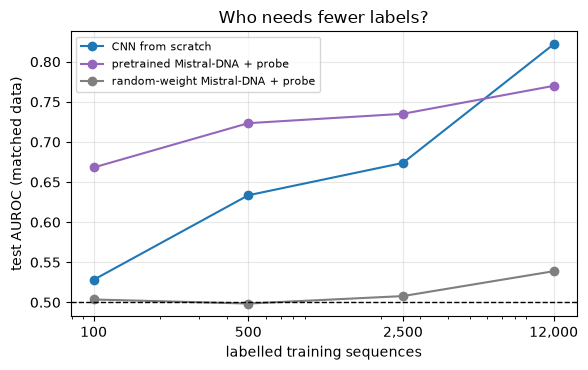

In [15]:
#@title Learn from fewer labels - run this cell, nothing to change (~3 min on a T4) { display-mode: "form" }
from transformers import AutoConfig, AutoModel
M_tr, my_tr, M_te, my_te = BENCH["matched"]
POOL = 12000
t0 = time.time()
D_pool, D_test = [to_dna(s) for s in M_tr[:POOL]], [to_dna(s) for s in M_te]
E_pool, E_test = embed(tok, fm, D_pool), embed(tok, fm, D_test)
torch.manual_seed(SEED)
fm_rand = AutoModel.from_config(AutoConfig.from_pretrained(FM_REPO)).to(DEVICE).eval()
R_pool, R_test = embed(tok, fm_rand, D_pool), embed(tok, fm_rand, D_test)
del fm_rand
X_pool, y_pool = encode_batch(M_tr[:POOL]), my_tr[:POOL]


def cnn_from_scratch(sel, seed=0):
    """Slot 2's CNN trained on `sel` only; stops early using 10% of `sel` (never the test set)."""
    sel = np.random.default_rng(seed).permutation(sel)
    nv = max(len(sel) // 10, 10)
    va, tr = sel[:nv], sel[nv:]
    torch.manual_seed(seed)
    model = GlobalCNN().to(DEVICE)
    opt = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    crit = nn.BCEWithLogitsLoss()
    bs = min(256, max(16, len(tr) // 8))
    epochs = int(np.clip(1500 / max(len(tr) // bs, 1), 6, 200))
    best, best_state, bad = -1, None, 0
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(tr))
        for i in range(0, len(tr), bs):
            b = tr[perm[i:i + bs].numpy()]
            opt.zero_grad()
            crit(model(X_pool[b].to(DEVICE)), torch.tensor(y_pool[b], dtype=torch.float32, device=DEVICE)).backward()
            opt.step()
        v = roc_auc_score(y_pool[va], score_sequences(model, [M_tr[i] for i in va]))
        if v > best:
            best, bad, best_state = v, 0, {k: t.clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= 8:
                break
    model.load_state_dict(best_state)
    return roc_auc_score(my_te, score_sequences(model, M_te))


NS = [100, 500, 2500, 12000]
curve = {"CNN from scratch": [], "pretrained Mistral-DNA + probe": [], "random-weight Mistral-DNA + probe": []}
for n in NS:
    sel = np.random.default_rng(n).choice(POOL, n, replace=False)
    C = 0.01 if n < 2500 else 0.1          # smaller training sets need a more cautious probe
    curve["pretrained Mistral-DNA + probe"].append(probe_auc(E_pool[sel], y_pool[sel], E_test, my_te, C)[0])
    curve["random-weight Mistral-DNA + probe"].append(probe_auc(R_pool[sel], y_pool[sel], R_test, my_te, C)[0])
    curve["CNN from scratch"].append(cnn_from_scratch(sel))
    print(f"{n:6,} labels | " + " | ".join(f"{k} {v[-1]:.3f}" for k, v in curve.items()))
print(f"({time.time() - t0:.0f}s)")

colors = {"CNN from scratch": "tab:blue", "pretrained Mistral-DNA + probe": "tab:purple",
          "random-weight Mistral-DNA + probe": "tab:grey"}
plt.figure(figsize=(6, 3.8))
for k, v in curve.items():
    plt.plot(NS, v, "o-", c=colors[k], label=k)
plt.axhline(0.5, ls="--", c="k", lw=1)
plt.xscale("log"); plt.xticks(NS, [f"{n:,}" for n in NS])
plt.xlabel("labelled training sequences"); plt.ylabel("test AUROC (matched data)")
plt.title("Who needs fewer labels?"); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### What to take away

* **Frozen**, the pretrained model mostly encodes composition: with plenty of labels the small CNN
  beats it; with few labels it wins clearly, where the CNN is close to a coin flip. The random-weight
  line stays flat, so that advantage was **learned from the genome**.
* **Fine-tuned**, a larger pretrained model beats the CNN at both ends: in our offline runs on the
  same matched data, NT-500M with LoRA reached 0.87 vs the CNN's 0.84 (20,000 labels) and 0.75 vs
  0.66 (500 labels). Your Mistral-DNA run is the small version of that experiment.
* Which model is "best" depends on how many labels you have, and on whether you fine-tune. You find
  out by testing: against a simple baseline, with a shuffle and a matched control (Slots 6–7).